# 01 CDRMIP Pr Monthly Pipeline

In [17]:
%load_ext autoreload
%autoreload 2
    
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import matplotlib.cm as cm
import xarray as xr


from cdrmip_extremes import (
        configs, pipeline, io_disk,
        file_search, processing,
        load_raw, extremes, utils, stats, plotting,
        gwl,
)
from cdrmip_extremes.extremes_pipeline import ExtremesPipeline
from cdrmip_extremes.load_processed import load_processed
from cdrmip_extremes.configs import PROC_DIR, CDR_MODELS

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
config = pipeline.PipelineConfig(
    experiments=[
        pipeline.ExperimentConfig(
            experiment_id='1pctCO2-cdr', table_id='Amon', variable_id='pr',
            anomaly_reference='picontrol',grid_label=None,
            crossing_gwls=[1.5,2,3], overshoot=True,
            gwl_match_period=(320, 340),
            rolling_window=21,
        ),
    ],
    realign_years_overrides={'1pctCO2': (0, 140)}
)

In [4]:
config = pipeline.CDRMIPPipeline(config)

In [5]:
pr_pipe = config.load_raw()

=== Loading 1pctCO2-cdr ===
Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'table_id': 'Amon', 'variable_id': 'pr', 'grid_label': None, 'member_id': None}
Loading ACCESS-ESM1-5 / r1i1p1f1
  0241-01-16 12:00:00 -> 1000-12-16 12:00:00
Loading CAS-ESM2-0 / r1i1p1f1
  0340-01-16 12:00:00 -> 0569-12-16 12:00:00
Loading CESM2 / r1i1p1f1
  0001-01-15 12:00:00 -> 0200-12-15 12:00:00
Loading CNRM-ESM2-1 / r1i1p1f2
  1990-01-16 12:00:00 -> 2189-12-16 12:00:00
Loading CanESM5 / r1i1p2f1
  1991-01-16 12:00:00 -> 2290-12-16 12:00:00
Loading GFDL-ESM4 / r1i1p1f1
  0141-01-16 12:00:00 -> 0340-12-16 12:00:00
Loading MIROC-ES2L / r1i1p1f2
  1989-01-16 12:00:00 -> 2490-12-16 12:00:00
Loading UKESM1-0-LL / r1i1p1f2
  1990-01-16 00:00:00 -> 2639-12-16 00:00:00


In [6]:
pr_pipe.concatenate_to_parents()

Searching for ACCESS-ESM1-5 1pctCO2-cdr r1i1p1f1 parent
Loading ACCESS-ESM1-5 1pctCO2 r1i1p1f1
Concatenating 1pctCO2-cdr -> 1pctCO2 [ACCESS-ESM1-5] via realign_years=(0, 140)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Searching for CAS-ESM2-0 1pctCO2-cdr r1i1p1f1 parent
Loading CAS-ESM2-0 1pctCO2 r1i1p1f1
Concatenating 1pctCO2-cdr -> 1pctCO2 [CAS-ESM2-0] via realign_years=(0, 140)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Searching for CESM2 1pctCO2-cdr r1i1p1f1 parent
Loading CESM2 1pctCO2 r1i1p1f1
Concatenating 1pctCO2-cdr -> 1pctCO2 [CESM2] via realign_years=(0, 140)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-15 12:00:00, child relabeled to start 0140-01-15 12:00:00)
Searching for CNRM-ESM2-1 1pctCO2-cdr r1i1p1f2 parent
Loading CNRM-ESM2-1 1pctCO2 r1i1p1f2
Concatenating 1pct

In [7]:
pr_pipe.load_picontrol()

Searching for ACCESS-ESM1-5 1pctCO2-cdr r1i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Searching for CAS-ESM2-0 1pctCO2-cdr r1i1p1f1 parent
Loading CAS-ESM2-0 piControl r1i1p1f1
Searching for CESM2 1pctCO2-cdr r1i1p1f1 parent
Loading CESM2 piControl r1i1p1f1
Searching for CNRM-ESM2-1 1pctCO2-cdr r1i1p1f2 parent
Loading CNRM-ESM2-1 piControl r1i1p1f2
Searching for CanESM5 1pctCO2-cdr r1i1p2f1 parent
Loading CanESM5 piControl r1i1p2f1
Searching for GFDL-ESM4 1pctCO2-cdr r1i1p1f1 parent
Loading GFDL-ESM4 piControl r1i1p1f1
Searching for MIROC-ES2L 1pctCO2-cdr r1i1p1f2 parent
Loading MIROC-ES2L piControl r1i1p1f2
Searching for UKESM1-0-LL 1pctCO2-cdr r1i1p1f2 parent
Loading UKESM1-0-LL piControl r1i1p1f2


In [8]:
pr_pipe.regrid()

Building regridder for grid (145,) x (192,)
Building regridder for grid (128,) x (256,)
Building regridder for grid (192,) x (288,)
Building regridder for grid (128,) x (256,)
Building regridder for grid (64,) x (128,)
Building regridder for grid (180,) x (288,)
Building regridder for grid (64,) x (128,)
Building regridder for grid (144,) x (192,)


In [9]:
pr_pipe.compute_anomalies()

## Load crossing years etc.

In [18]:
gsat = load_processed(PROC_DIR, 'CDRMIP', 'gsat', category='gsat_all', model_order=CDR_MODELS)
gsat_rolling = load_processed(PROC_DIR, 'CDRMIP', 'gsat_rolling', category='gsat_rolling_all', model_order=CDR_MODELS)
crossing_years = load_processed(PROC_DIR, 'CDRMIP', 'crossing_years', category='crossing_years_all', model_order=CDR_MODELS)
gwl_matching_years = load_processed(PROC_DIR, 'CDRMIP', 'gwl_matching_years', category='gwl_matching_years_all', model_order=CDR_MODELS)

## Evaluate pr at relevant periods

In [19]:
pr_periods, pr_reversibility = gwl.extract_gwl_periods(
    pr_pipe.anomaly, crossing_years, pr_pipe.config.experiments, varname='pr'
)
pr_differences = gwl.gwl_matched_differences(
    gwl_matching_years, pr_pipe.anomaly, pr_pipe.config.experiments, varname='pr'
)

In [109]:
pr_reversibility_mmday = {
    model: {expt: {member: da * 86400 for member, da in member_dt.items()}
            for expt, member_dt in expt_dict.items()}
    for model, expt_dict in pr_reversibility.items()
}

In [110]:
pr_reversibility

{'ACCESS-ESM1-5': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 194kB
   dask.array<sub, shape=(3, 90, 180), dtype=float32, chunksize=(1, 90, 180), chunktype=numpy.ndarray>
   Coordinates:
     * gwl      (gwl) float64 24B 1.5 2.0 3.0
     * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
     * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0}},
 'CESM2': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 194kB
   dask.array<sub, shape=(3, 90, 180), dtype=float32, chunksize=(1, 90, 180), chunktype=numpy.ndarray>
   Coordinates:
     * gwl      (gwl) float64 24B 1.5 2.0 3.0
     * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
     * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0}},
 'CNRM-ESM2-1': {'1pctCO2-cdr': {'r1i1p1f2': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 194kB
   dask.arr

In [20]:
pr_pipe.gwl_differences = pr_differences
pr_pipe.compute_member_ensemble('gwl_differences', reduction='median', save_as='gwl_differences_median')
pr_pipe.compute_multi_model_stat('gwl_differences_median', reduction='median', save_as='gwl_differences_median_multimodel')

{'ACCESS-ESM1-5': {'1pctCO2-cdr': <xarray.DataArray 'pr' (lat: 90, lon: 180)> Size: 130kB
  dask.array<nanmedian, shape=(90, 180), dtype=float64, chunksize=(90, 180), chunktype=numpy.ndarray>
  Coordinates:
    * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
    * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0},
 'CanESM5': {'1pctCO2-cdr': <xarray.DataArray 'pr' (lat: 90, lon: 180)> Size: 130kB
  dask.array<nanmedian, shape=(90, 180), dtype=float64, chunksize=(90, 180), chunktype=numpy.ndarray>
  Coordinates:
    * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
    * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0},
 'CESM2': {'1pctCO2-cdr': <xarray.DataArray 'pr' (lat: 90, lon: 180)> Size: 130kB
  dask.array<nanmedian, shape=(90, 180), dtype=float64, chunksize=(90, 180), chunktype=numpy.ndarray>
  Coordinates:
    * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 8

In [21]:
pr_pipe.gwl_reversibility = pr_reversibility
pr_pipe.compute_member_ensemble('gwl_reversibility', reduction='median', save_as='gwl_reversibility_median')
pr_pipe.compute_multi_model_stat('gwl_reversibility_median', reduction='median', save_as='gwl_reversibility_median_multimodel')

{'ACCESS-ESM1-5': {'1pctCO2-cdr': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 389kB
  dask.array<nanmedian, shape=(3, 90, 180), dtype=float64, chunksize=(1, 90, 180), chunktype=numpy.ndarray>
  Coordinates:
    * gwl      (gwl) float64 24B 1.5 2.0 3.0
    * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
    * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0},
 'CESM2': {'1pctCO2-cdr': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 389kB
  dask.array<nanmedian, shape=(3, 90, 180), dtype=float64, chunksize=(1, 90, 180), chunktype=numpy.ndarray>
  Coordinates:
    * gwl      (gwl) float64 24B 1.5 2.0 3.0
    * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
    * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0},
 'CNRM-ESM2-1': {'1pctCO2-cdr': <xarray.DataArray 'pr' (gwl: 3, lat: 90, lon: 180)> Size: 389kB
  dask.array<nanmedian, shape=(3, 90, 180), dtype=

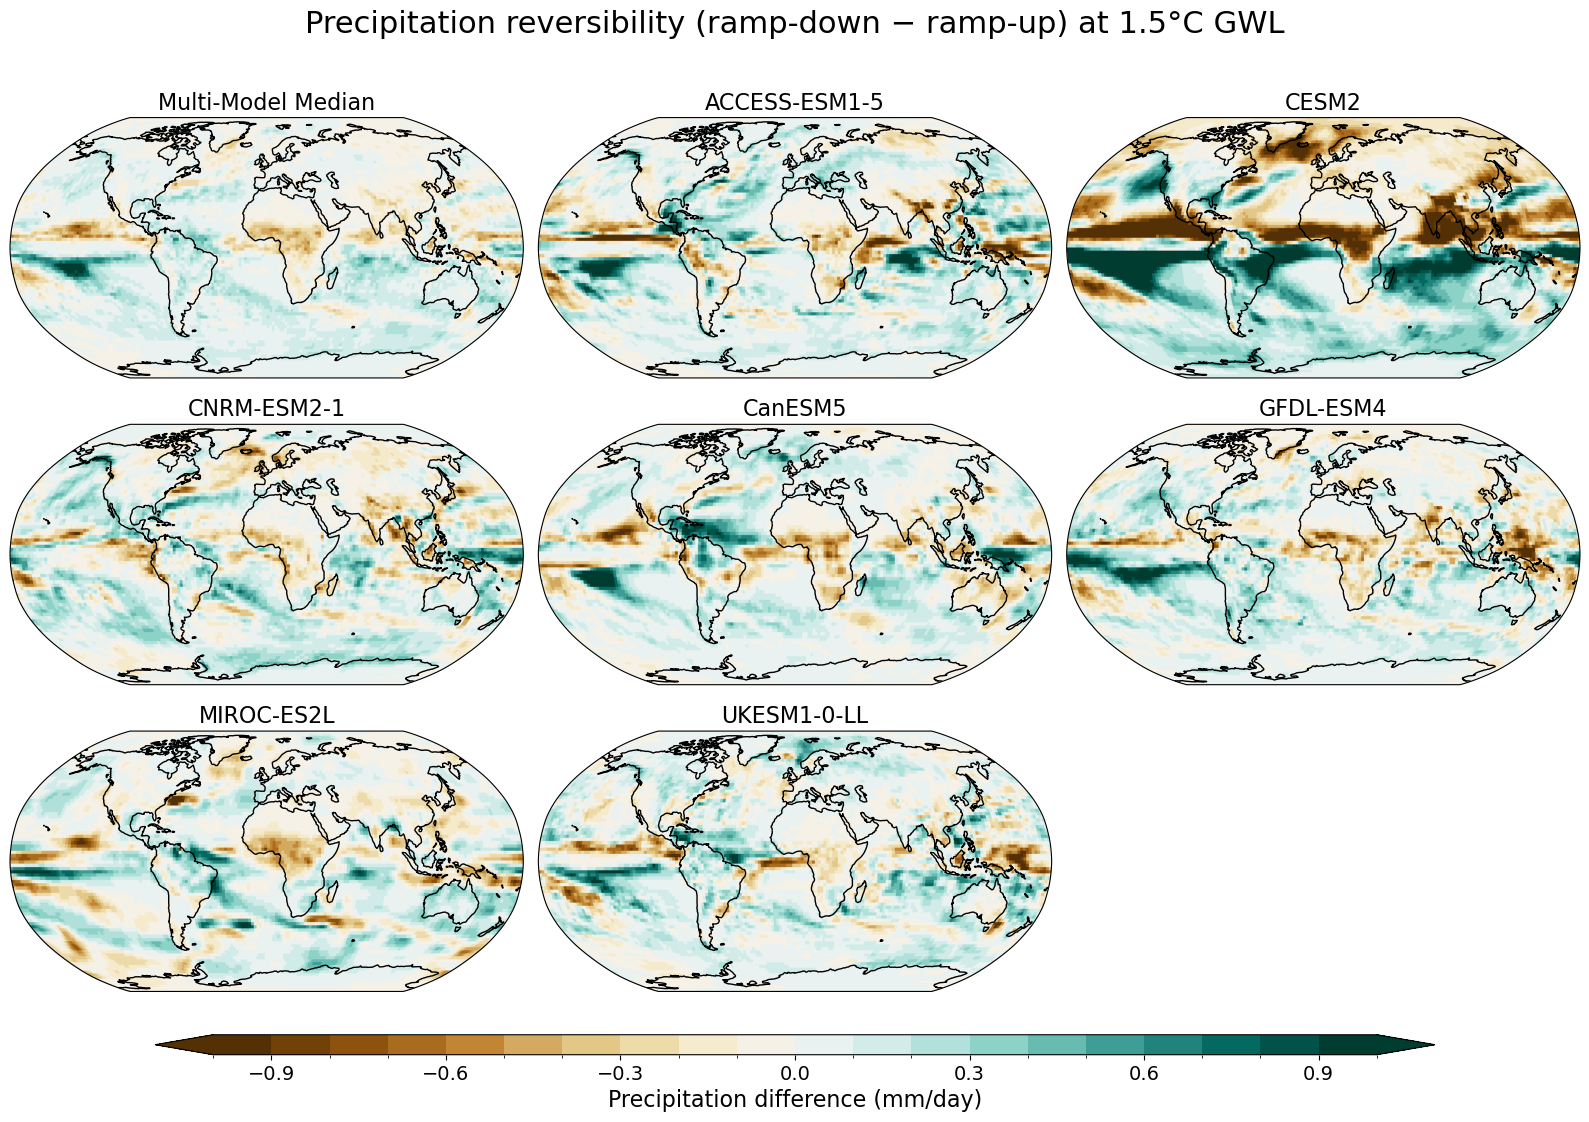

In [22]:
fig = plotting.plot_gwl_diff(
    pr_pipe.gwl_reversibility_median_multimodel, expt='1pctCO2-cdr', varname='pr', gwl=1.5,
    levels=np.linspace(-1, 1, 21),
    cmap=cm.BrBG,
    cbar_label="Precipitation difference (mm/day)",
    suptitle="Precipitation reversibility (ramp-down − ramp-up) at 1.5°C GWL",
)

## Calculate global mean

In [23]:
global_mean = utils._map_leaves(pr_pipe.anomaly, lambda ds: utils.global_mean(ds, var='pr'))
global_mean

{'ACCESS-ESM1-5': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.DataArray 'pr' (year: 900)> Size: 7kB
   dask.array<truediv, shape=(900,), dtype=float64, chunksize=(31,), chunktype=numpy.ndarray>
   Coordinates:
     * year     (year) int64 7kB 0 1 2 3 4 5 6 7 ... 893 894 895 896 897 898 899}},
 'CAS-ESM2-0': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.DataArray 'pr' (year: 370)> Size: 3kB
   dask.array<truediv, shape=(370,), dtype=float64, chunksize=(31,), chunktype=numpy.ndarray>
   Coordinates:
     * year     (year) int64 3kB 0 1 2 3 4 5 6 7 ... 363 364 365 366 367 368 369}},
 'CESM2': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.DataArray 'pr' (year: 340)> Size: 3kB
   dask.array<truediv, shape=(340,), dtype=float64, chunksize=(30,), chunktype=numpy.ndarray>
   Coordinates:
     * year     (year) int64 3kB 0 1 2 3 4 5 6 7 ... 333 334 335 336 337 338 339}},
 'CNRM-ESM2-1': {'1pctCO2-cdr': {'r1i1p1f2': <xarray.DataArray 'pr' (year: 340)> Size: 3kB
   dask.array<truediv, shape=(340,), dtype=float64, chunksi

In [24]:
global_mean_median = stats.reduce_member_tree(global_mean, reduction='median')

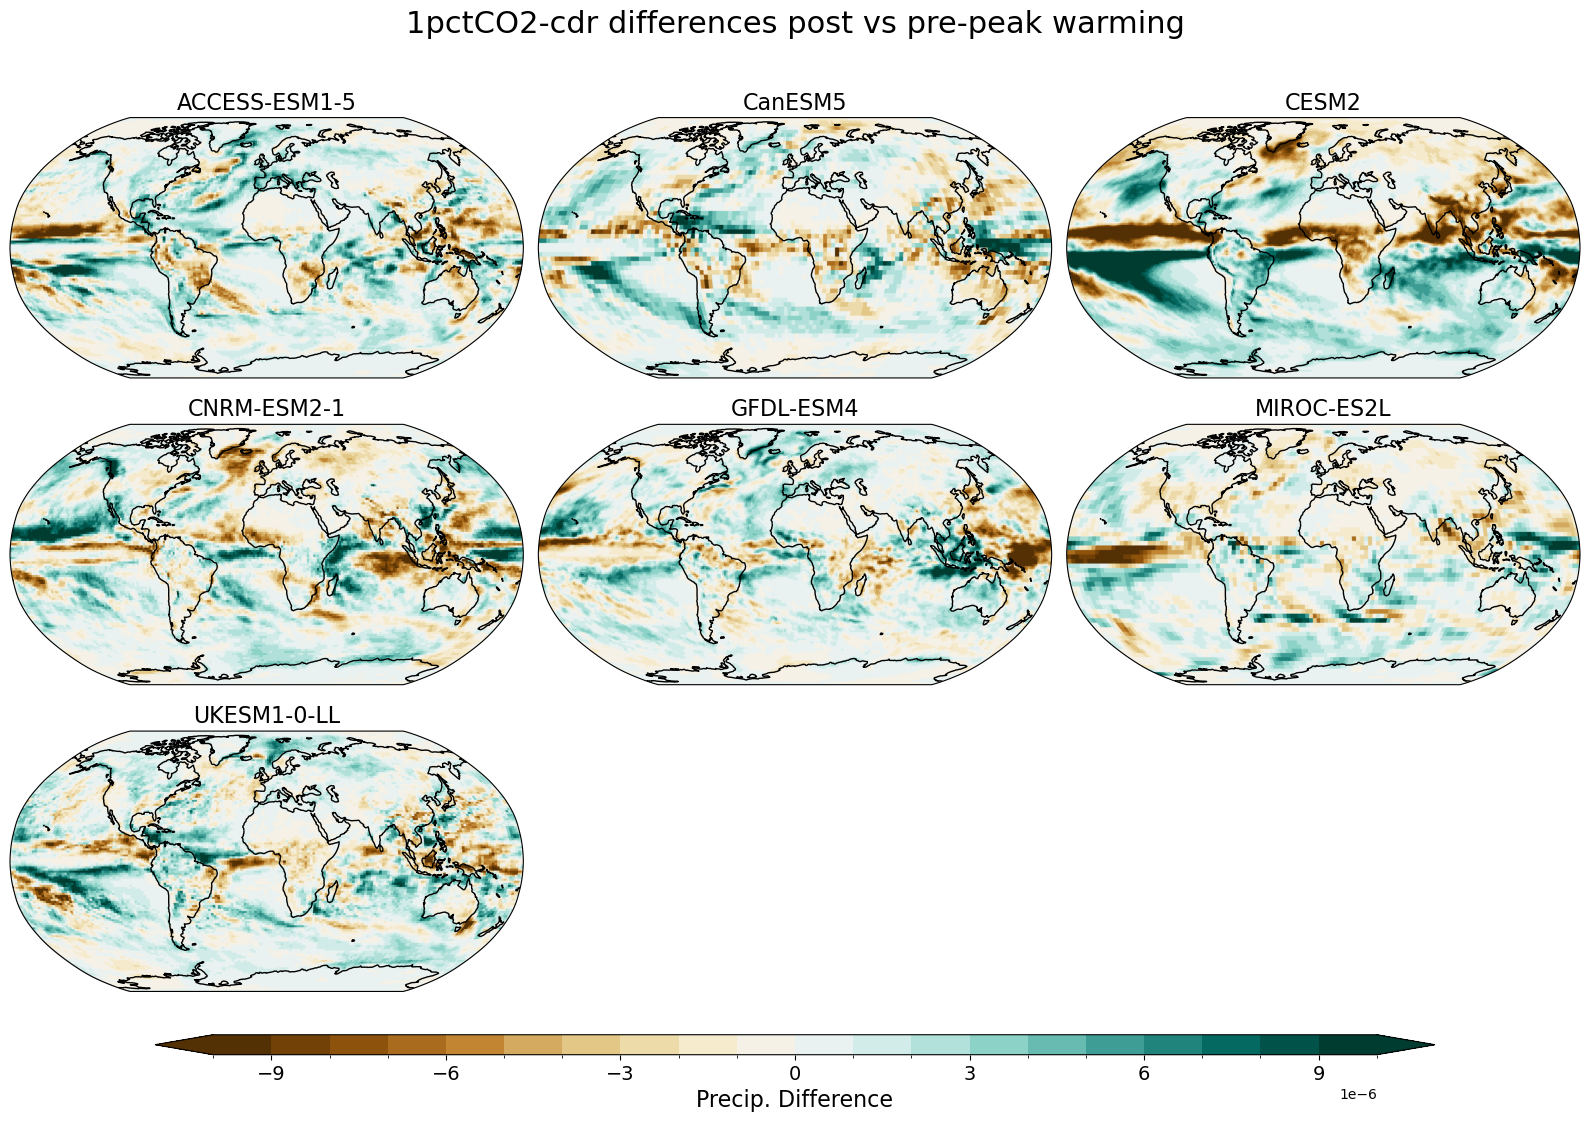

In [76]:
fig = plotting.plot_gwl_diff(
    pr_pipe.gwl_differences_median,
    expt='1pctCO2-cdr',
    varname='pr',
    cbar_label='Precip. Difference',
    levels = np.linspace(-1e-5,1e-5,21),
    cmap='BrBG'
)


# Save

In [ ]:
pipe.save(
    configs.PROC_DIR,
    'CDRMIP',
    array_outputs={
        'rx1day': (pipe.rxnday_anomaly[1], 'rx1day'),
        'rx5day': (pipe.rxnday_anomaly[5], 'rx5day'),
    },
    overwrite=False
)